<a href="https://colab.research.google.com/github/magnogomes874/SSD-/blob/main/MVP%20PSP%208.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MVP 1 — SEGURANÇA CIBERNÉTICA**

Magno Gomes Sousa — 200031031

**Professor:** André Luiz Marques Serrano

**Tema:** Pipeline de dados em nuvem e comparação entre Random Forest e rede neural com três camadas ocultas.

**Objetivo:** Detectar tráfego normal e ataques para apoiar uma empresa de armazenamento de dados em um cenário proposto Multi-Cloud. A UNSW-NB15 contém tráfego de laboratório e não identifica provedores.


**Organização:** Problema e coleta; leitura e integridade; limpeza; modelo flat e catálogo; qualidade; análise exploratória; ajuste,validação e teste; pré-processamento; Random Forest; rede neural; avaliação; interpretação; armazenamento no Drive; conclusão e autoavaliação.

**1. Resumo executivo**

Foi construído um pipeline para detectar tráfego normal e ataques no cenário de uma empresa de armazenamento de dados. O processamento foi executado no Google Colab e os dados foram persistidos no Google Drive. O estudo compara Random Forest com uma rede neural densa de três camadas ocultas, com 128, 64 e 32 neurônios. A base utilizada é a UNSW-NB15, obtida no Kaggle.

Após a limpeza, foram preservados 107.740 registros de treino e 55.945 de teste. A Random Forest foi o candidato selecionado pela Average Precision da validação. No teste completo, com limiar 0,5, detectou 98,10% dos ataques, com 28,02% de falsos positivos entre os registros normais. Um limiar mais restritivo reduziu a FPR para 4,13%, mas o recall caiu para 80,80%.

A conclusão é favorável à viabilidade técnica de um protótipo de apoio à detecção. A escolha do ponto de operação exige definir o custo de falsos alarmes e de ataques não detectados. O experimento não comprova segurança de produção, retorno financeiro ou desempenho entre provedores de nuvem.

**2. Problema, objetivo e perguntas**
Uma equipe de segurança precisa identificar tráfego suspeito sem sobrecarregar a operação com alertas indevidos. O objetivo é construir um pipeline reproduzível de coleta, transformação, modelagem, carga e análise e comparar dois classificadores para apoiar essa decisão.

As perguntas que organizam a análise são:
- Como se distribuem o tráfego normal e os ataques nas partições usadas no experimento?
- Qual modelo apresenta melhor discriminação na validação e qual desempenho apresenta no teste?
- Qual é o compromisso entre ataques detectados e falsos alarmes ao modificar o limiar?
- Quais categorias de ataque apresentam menor detecção?
- Como os resultados mudam no recorte sem vetores iguais aos do treino?
- Quais tempos de treinamento e inferência foram observados?

O termo Multi-Cloud descreve o contexto proposto de aplicação. Os dados são de laboratório e não possuem campos que identifiquem provedores. A implementação do armazenamento usa o Google Drive.

**3. Preparar o ambiente**

Usamos Python/Pandas para ETL, SQLite para o modelo flat, Matplotlib para os gráficos e scikit-learn para os classificadores. A rede é um MLPClassifier com camadas ocultas 128/64/32, ReLU e Adam. Não há dependência de TensorFlow.

A semente 42 torna a aleatoriedade controlada. Isso não garante resultados idênticos entre versões de bibliotecas. A execução original usou scikit-learn 1.6.1, NumPy 2.1.3 e Pandas 2.2.3.

O código registra o ambiente efetivamente utilizado.

In [10]:
# Bibliotecas de leitura, transformação, armazenamento e modelagem.
import copy
import hashlib
import json
import os
import platform
import re
import shutil
import sqlite3
import time
import unicodedata
import uuid
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Markdown, SVG
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, log_loss, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

# Duas escolhas de execução; o restante do protocolo é definido abaixo.
RETREINAR_MODELOS = False
SALVAR_NO_DRIVE = True
CAMINHO_PACOTE = ""  # Opcional: caminho de MVP3_DADOS_RELATORIO_COMPLETO.zip.
try:
    from google.colab import files
    EM_COLAB = True
except ImportError:
    EM_COLAB = False
EXECUCAO = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
TRABALHO = Path('/content' if EM_COLAB else '.') / ('mvp3_explicado_' + EXECUCAO)
TRABALHO.mkdir(parents=True, exist_ok=False)
SAIDA = TRABALHO / 'entrega'
SAIDA.mkdir()
(SAIDA / 'graficos').mkdir()

VERSOES = {'python': platform.python_version(), 'numpy': np.__version__,
           'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
           'joblib': joblib.__version__}
print('Execução:', EXECUCAO)
print('Modo:', 'novo treinamento' if RETREINAR_MODELOS else 'conferência dos resultados originais')
display(pd.Series(VERSOES, name='versão atual').to_frame())


Execução: 20261021T193440Z_24d060b6
Modo: conferência dos resultados originais


,versão atual
python,3.13.16
numpy,2.1.3
pandas,2.2.3
scikit_learn,1.6.1
joblib,1.6.0


**4. Busca, coleta, origem e condições de uso**

- Base: UNSW-NB15.
- Espelho usado: Kaggle — mrwellsdavid/unsw-nb15.
- Documentação primária: UNSW Research.
- Recorte efetivamente usado: duas partições preparadas de 45 colunas, totalizando 257.673 linhas antes da limpeza. Os quatro CSVs brutos de outro esquema não foram concatenados a essas partições.

O próximo bloco seleciona somente o pacote consolidado. Ele não deve receber modelo_catalogo.zip isoladamente nem um ZIP de evidências de outra etapa.

In [11]:
# Funções pequenas de integridade e escrita de metadados.
def exigir(condicao, mensagem):
    if not condicao:
        raise ValueError(mensagem)

def sha256(arquivo):
    h = hashlib.sha256()
    with Path(arquivo).open('rb') as f:
        for bloco in iter(lambda: f.read(1024 * 1024), b''):
            h.update(bloco)
    return h.hexdigest()

def ler_json(arquivo):
    return json.loads(Path(arquivo).read_text(encoding='utf-8'))

def salvar_json(arquivo, objeto):
    def nativo(x):
        if isinstance(x, np.generic):
            return x.item()
        if isinstance(x, Path):
            return str(x)
        raise TypeError(type(x).__name__)
    Path(arquivo).write_text(json.dumps(objeto, ensure_ascii=False, indent=2,
                                      default=nativo, allow_nan=False), encoding='utf-8')

if CAMINHO_PACOTE:
    pacote_dados = Path(CAMINHO_PACOTE)
else:
    candidatos = sorted(Path('/content' if EM_COLAB else '.').glob('MVP3_DADOS_RELATORIO_COMPLETO*.zip'))
    if len(candidatos) == 1:
        pacote_dados = candidatos[0]
    elif EM_COLAB:
        from google.colab import files
        print('Selecione somente MVP3_DADOS_RELATORIO_COMPLETO.zip.')
        enviados = files.upload()
        exigir(len(enviados) == 1, 'Envie um único pacote consolidado.')
        pacote_dados = Path(next(iter(enviados)))
        del enviados
    else:
        raise ValueError('Preencha CAMINHO_PACOTE com o caminho do pacote consolidado.')
exigir(pacote_dados.is_file(), 'Pacote não encontrado; revise CAMINHO_PACOTE.')
print('Entrada:', pacote_dados.name)


Selecione somente MVP3_DADOS_RELATORIO_COMPLETO.zip.


Saving MVP3_DADOS_RELATORIO_COMPLETO.zip to MVP3_DADOS_RELATORIO_COMPLETO.zip
Entrada: MVP3_DADOS_RELATORIO_COMPLETO.zip


**Conferencia do conteúdo antes da analise**

O manifesto associa cada arquivo ao seu hash. A extração confere o conteúdo e rejeita caminhos inesperados e nomes duplicados. Os arquivos .joblib históricos são apenas conferidos por hash; a análise dos resultados utiliza CSVs de predições, sem carregar objetos de modelos de outra versão.

Essa conferência detecta alteração dos bytes em relação ao manifesto, mas não certifica a origem de um pacote arbitrário. O material de referência é o pacote do próprio trabalho.

In [12]:
# Extração controlada: valida todos os hashes listados e preserva as entradas.
def abrir_pacote_verificado(arquivo, destino, nome_manifesto, ignorar_modelos=False):
    destino = Path(destino)
    destino.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(arquivo) as z:
        nomes = [i.filename for i in z.infolist() if not i.is_dir()]
        exigir(len(nomes) == len(set(nomes)), 'ZIP com nomes duplicados.')
        exigir(nome_manifesto in nomes, f'Pacote incorreto: falta {nome_manifesto}.')
        manifesto = json.loads(z.read(nome_manifesto))
        hashes = manifesto['arquivos_sha256']
        for nome, esperado in hashes.items():
            rel = Path(nome)
            exigir(not rel.is_absolute() and '..' not in rel.parts and chr(92) not in nome,
                   'Caminho inválido no pacote.')
            exigir(nome in nomes, f'Arquivo ausente: {nome}')
            h = hashlib.sha256()
            destino_arquivo = destino / rel
            gravar = not (ignorar_modelos and rel.suffix == '.joblib')
            if gravar:
                destino_arquivo.parent.mkdir(parents=True, exist_ok=True)
                saida = destino_arquivo.open('wb')
            else:
                saida = None
            try:
                with z.open(nome) as origem:
                    for bloco in iter(lambda: origem.read(1024 * 1024), b''):
                        h.update(bloco)
                        if saida is not None:
                            saida.write(bloco)
            finally:
                if saida is not None:
                    saida.close()
            exigir(h.hexdigest() == esperado, f'Hash divergente: {nome}')
        (destino / nome_manifesto).write_bytes(z.read(nome_manifesto))
    return manifesto

ENTRADAS = TRABALHO / 'entradas'
manifesto_pacote = abrir_pacote_verificado(pacote_dados, ENTRADAS, 'manifesto_pacote.json')
exigir(manifesto_pacote['tipo'] == 'MVP3_DADOS_RELATORIO_COMPLETO', 'Tipo de pacote incorreto.')
ORIGINAIS_ZIP = ENTRADAS / 'dados/particoes_originais.zip'
MODELO_ZIP = ENTRADAS / 'dados/modelo_catalogo.zip'
RESULTADOS_ZIP = ENTRADAS / 'resultados/etapa4_resultados.zip'
MODELO_REF = TRABALHO / 'modelo_referencia'
RESULTADOS_REF = TRABALHO / 'resultados_referencia'
manifesto_modelo = abrir_pacote_verificado(MODELO_ZIP, MODELO_REF, 'manifesto_modelagem.json')
manifesto_resultados = abrir_pacote_verificado(
    RESULTADOS_ZIP, RESULTADOS_REF, 'manifesto_analise.json', ignorar_modelos=True)
exigir(manifesto_resultados['sha256_zip_entrada'] == sha256(MODELO_ZIP),
       'Os resultados não correspondem a este modelo de dados.')
fonte = ler_json(ENTRADAS / 'metadados/fonte_confirmada.json')
config = ler_json(RESULTADOS_REF / 'configuracao.json')
resumo_original = ler_json(RESULTADOS_REF / 'resumo_analise.json')
print('Pacote consolidado, catálogo e resultados: hashes conferidos.')
display(pd.Series(fonte).to_frame('metadados de origem'))


Pacote consolidado, catálogo e resultados: hashes conferidos.


,metadados de origem
autor,Magno Gomes Sousa
matricula,200031031
instituicao,Universidade de Brasilia — Departamento de Eng...
kaggle,https://www.kaggle.com/datasets/mrwellsdavid/u...
kaggle_canonico,https://www.kaggle.com/datasets/mrwellsdavid/u...
data_download,2026-10-21
data_download_informada_pelo_autor,True
fonte_oficial,https://research.unsw.edu.au/projects/unsw-nb1...
data_captura_trafego,Nao identificavel nas particoes preparadas; na...
condicoes_uso,Pesquisa academica autorizada na documentacao ...


# 5. Pipeline e decisões de transformação

Fluxo: download manual do Kaggle → leitura das duas partições → limpeza determinística e auditoria → tabela flat e catálogo → persistência no Drive → divisão por grupos → pré-processamento aprendido no ajuste → treinamento → validação → teste final → relatório e evidências.

Na cópia recebida, os nomes dos arquivos divergem dos tamanhos de treino/teste descritos na documentação. Foi adotado o critério registrado de tamanhos: UNSW_NB15_testing-set.csv, com 175.341 linhas, foi tratado como treino; UNSW_NB15_training-set.csv, com 82.332, como teste. Esse mapeamento foi preservado e os hashes dos CSVs de origem foram registrados. Não se deve interpretar essa escolha como validação semântica independente de que o espelho manteve a divisão original.

**As regras de limpeza foram:**
- Conversão de tipos, verificação de valores numéricos e preservação de zeros válidos.
- Texto em minúsculas, sem espaços excedentes e com padronização de categorias. Hífens legítimos, como em serviços de rede, foram preservados.
- O marcador - de serviço foi convertido em nao_identificado; a categoria backdoors foi padronizada para backdoor.
- Valores de is_ftp_login fora do domínio binário foram auditados e representados por -1, sem aprender estatísticas da base de teste.
- Duplicatas foram removidas pelo conteúdo completo, excluindo identificador e campos de origem e incluindo os rótulos. A primeira ocorrência foi preservada.
- Extremos plausíveis foram mantidos. Limites descritivos por IQR não foram usados para eliminar registros.
- Vetores iguais com rótulos conflitantes foram preservados e quantificados. A igualdade de atributos não prova que duas conexões reais sejam o mesmo evento.
- As partições não contêm colunas de calendário. Duração e intervalos de rede são medidas, e não datas a converter.
Partição	Entrada	Duplicatas removidas	Saída	Marcadores -1
treino	175341	67601	107740	9
teste	82332	26387	55945	1


Foram retiradas 93.988 duplicatas de conteúdo nas duas partições, sem registros em quarentena. A deduplicação altera a distribuição e limita a comparação direta com experimentos que usam os arquivos preparados sem esse tratamento.

**5.1. Definir o esquema e ler as duas partições**

A lista de preditores é explícita. label será a resposta supervisionada; attack_cat informa a categoria para análise de erros. Ambos ficam fora das entradas dos modelos. Os campos de origem permitem reconstruir qual registro do CSV originou cada linha.

keep_default_na=False evita que uma categoria textual legítima seja interpretada como ausência. A leitura mantém os valores como texto até que cada regra de tipo seja aplicada.

In [16]:
FONTE_OFICIAL = "https://research.unsw.edu.au/projects/unsw-nb15-dataset"
TEXTOS = ["proto", "service", "state", "attack_cat"]
CONTINUAS = [
    "dur", "rate", "sload", "dload", "sinpkt", "dinpkt", "sjit", "djit",
    "tcprtt", "synack", "ackdat",
]
ATRIBUTOS = [
    "dur", "proto", "service", "state", "spkts", "dpkts", "sbytes", "dbytes",
    "rate", "sttl", "dttl", "sload", "dload", "sloss", "dloss", "sinpkt",
    "dinpkt", "sjit", "djit", "swin", "stcpb", "dtcpb", "dwin", "tcprtt",
    "synack", "ackdat", "smean", "dmean", "trans_depth", "response_body_len",
    "ct_srv_src", "ct_state_ttl", "ct_dst_ltm", "ct_src_dport_ltm",
    "ct_dst_sport_ltm", "ct_dst_src_ltm", "is_ftp_login", "ct_ftp_cmd",
    "ct_flw_http_mthd", "ct_src_ltm", "ct_srv_dst", "is_sm_ips_ports",
]
NUMERICAS = [c for c in ATRIBUTOS if c not in TEXTOS]
INTEIRAS = [c for c in NUMERICAS if c not in CONTINUAS]
COLUNAS = ["id", *ATRIBUTOS, "attack_cat", "label"]
CONTEUDO = [*ATRIBUTOS, "attack_cat", "label"]
CATEGORIAS_ATAQUE = {
    "analysis", "backdoor", "dos", "exploits", "fuzzers", "generic",
    "reconnaissance", "shellcode", "worms",
}
MAXIMOS = {"sttl": 255, "dttl": 255, "swin": 65535, "dwin": 65535,
           "stcpb": 4294967295, "dtcpb": 4294967295}
BINARIAS = ["is_ftp_login", "is_sm_ips_ports"]
AUSENTE_NUMERICO = -1
METADADOS = ["arquivo_origem", "registro_origem"]


In [17]:
def normalizar_nome(valor):
    texto = unicodedata.normalize("NFKD", str(valor)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9_]+", "_", texto.strip().lower()).strip("_")


def normalizar_texto(serie):
    return (serie.astype("string").fillna("").str.normalize("NFKD")
            .str.encode("ascii", errors="ignore").str.decode("ascii")
            .str.lower().str.strip().str.replace(r"\s+", " ", regex=True))


def ler_particoes(caminho_zip):
    """Le direto do ZIP, sem extrair todos os arquivos nem sobrescrever originais."""
    dados, inventario, hashes = {}, [], {}
    with zipfile.ZipFile(caminho_zip) as pacote:
        for info in pacote.infolist():
            inventario.append({"arquivo": info.filename, "bytes_descompactados": info.file_size})
            nome = Path(info.filename).name.lower()
            if nome not in {"unsw_nb15_training-set.csv", "unsw_nb15_testing-set.csv"}:
                continue
            if nome in dados:
                raise ValueError(f"Mais de um arquivo com o mesmo nome: {nome}")
            # keep_default_na=False preserva categorias literais como o estado 'no'.
            with pacote.open(info) as arquivo:
                df = pd.read_csv(arquivo, dtype=str, keep_default_na=False,
                                 encoding="utf-8-sig", on_bad_lines="error")
            df.columns = [normalizar_nome(c) for c in df.columns]
            if df.columns.duplicated().any() or set(df.columns) != set(COLUNAS):
                raise ValueError(f"Esquema inesperado em {info.filename}: {list(df.columns)}")
            df = df[COLUNAS].copy()
            df["arquivo_origem"] = info.filename
            # Numero do registro de dados, comecando em 1, nao numero fisico da linha.
            df["registro_origem"] = np.arange(1, len(df) + 1, dtype=np.int64)
            dados[nome] = df
            resumo_hash = hashlib.sha256()
            with pacote.open(info) as arquivo:
                for bloco in iter(lambda: arquivo.read(1024 * 1024), b""):
                    resumo_hash.update(bloco)
            hashes[nome] = resumo_hash.hexdigest()
    if len(dados) != 2:
        raise ValueError("O ZIP deve conter as duas particoes UNSW_NB15_*ing-set.csv.")
    return dados, inventario, hashes


def escolher_particoes(dados, criterio):
    avisos = []
    if criterio == "tamanhos_documentados":
        grandes = [nome for nome, df in dados.items() if len(df) == 175341]
        pequenas = [nome for nome, df in dados.items() if len(df) == 82332]
        if len(grandes) != 1 or len(pequenas) != 1:
            raise ValueError("Tamanhos diferentes dos documentados. Confira a origem ou use criterio='nomes'.")
        nome_treino, nome_teste = grandes[0], pequenas[0]
        if "training-set" not in nome_treino:
            avisos.append("Nomes divergem dos tamanhos oficiais. Adotado treino=175341 e teste=82332; confira o mapeamento registrado.")
    elif criterio == "nomes":
        nome_treino = "unsw_nb15_training-set.csv"
        nome_teste = "unsw_nb15_testing-set.csv"
        avisos.append("Papeis definidos pelos nomes dos arquivos; tamanhos podem divergir da documentacao oficial.")
    else:
        raise ValueError("Criterio deve ser 'tamanhos_documentados' ou 'nomes'.")
    return {"treino": nome_treino, "teste": nome_teste}, avisos

originais, inventario, hashes_csv = ler_particoes(ORIGINAIS_ZIP)
mapeamento, avisos = escolher_particoes(originais, 'tamanhos_documentados')
origem_historica = ler_json(MODELO_REF / 'linhagem.json')
exigir(hashes_csv == origem_historica['sha256_csvs_originais'], 'CSV diferente do utilizado no trabalho.')
display(pd.DataFrame([{'papel': p, 'arquivo': n, 'registros': len(originais[n])}
                      for p, n in mapeamento.items()]))
for aviso in avisos:
    print(aviso)


,papel,arquivo,registros
0,treino,unsw_nb15_testing-set.csv,175341
1,teste,unsw_nb15_training-set.csv,82332


Nomes divergem dos tamanhos oficiais. Adotado treino=175341 e teste=82332; confira o mapeamento registrado.


**5.2. Limpar sem aprender estatísticas do teste**

O próximo bloco implementa as regras do relatório. Valores inválidos recebem o marcador constante -1. A mediana será aprendida somente no ajuste, em uma etapa posterior. Células inválidas são auditadas antes da deduplicação; por isso o total de ocorrências originais não precisa ser igual ao número de marcadores restantes.

Duplicatas de conteúdo consideram os 42 atributos e os dois rótulos, excluindo o identificador e a posição de origem. Isso preserva vetores iguais com rótulos conflitantes para análise, em vez de escolher arbitrariamente um rótulo. Registros com alvo ou categoria incoerente seriam separados em quarentena.

In [18]:
def limpar_particao(original):
    df = original.copy()
    auditoria = []
    resumo = {"registros_entrada": len(df),
              "duplicatas_exatas_com_id": int(df.duplicated(subset=COLUNAS).sum())}

    def registrar(mascara, coluna, regra, destino):
        mascara = mascara.fillna(False)
        if not mascara.any():
            return
        parte = df.loc[mascara, METADADOS].copy()
        parte["coluna"] = coluna
        parte["valor_original"] = original.loc[parte.index, coluna].astype(str)
        parte["regra"] = regra
        parte["destino"] = destino
        auditoria.append(parte)

    # Padroniza somente campos de texto reais; '-' em service tem significado.
    for coluna in TEXTOS:
        df[coluna] = normalizar_texto(df[coluna])
    df["service"] = df["service"].replace({"-": "nao_identificado", "": "nao_identificado"})
    for coluna in ["proto", "state"]:
        df[coluna] = df[coluna].replace("", "nao_informado")
    df["attack_cat"] = df["attack_cat"].replace({"backdoors": "backdoor"})

    # Sem rotulo valido nao existe alvo supervisionado: separa em quarentena.
    df["label"] = pd.to_numeric(df["label"], errors="coerce")
    df["id"] = pd.to_numeric(df["id"], errors="coerce")
    alvo_invalido = ~df["label"].isin([0, 1])
    id_invalido = (~np.isfinite(df["id"]) | (df["id"] <= 0)
                   | (df["id"] % 1 != 0) | (df["id"] >= float(2 ** 63)))
    normal_sem_categoria = (df["label"] == 0) & (df["attack_cat"] == "")
    registrar(normal_sem_categoria, "attack_cat", "rotulo_0_sem_categoria", "normal")
    df.loc[normal_sem_categoria, "attack_cat"] = "normal"
    categoria_invalida = ~df["attack_cat"].isin(CATEGORIAS_ATAQUE | {"normal"})
    incoerente = ((df["label"] == 0) & (df["attack_cat"] != "normal")) | (
        (df["label"] == 1) & (df["attack_cat"] == "normal"))
    rejeitar = alvo_invalido | id_invalido | categoria_invalida | incoerente
    motivos = pd.Series("", index=df.index, dtype="string")
    for mascara, motivo in [(alvo_invalido, "rotulo_invalido"), (id_invalido, "id_invalido"),
                            (categoria_invalida, "categoria_invalida"), (incoerente, "rotulo_categoria_incoerentes")]:
        motivos.loc[mascara] += motivo + ";"
    quarentena = original.loc[rejeitar].copy()
    quarentena["motivo"] = motivos.loc[rejeitar]
    df = df.loc[~rejeitar].copy()
    df[["id", "label"]] = df[["id", "label"]].astype("int64")

    # Zero e medida valida de trafego: nunca e convertido automaticamente em nulo.
    # Ausencia/erro recebe -1, valor fora do dominio nao negativo das medidas.
    # Marcador constante evita aprender medianas/modas antes da futura validacao.
    for coluna in NUMERICAS:
        texto = original.loc[df.index, coluna].astype("string").str.strip()
        valores = pd.to_numeric(texto, errors="coerce").astype("float64")
        invalido = ~np.isfinite(valores) | (valores < 0)
        if coluna in INTEIRAS:
            invalido |= valores % 1 != 0
            invalido |= valores >= float(2 ** 63)
        if coluna in MAXIMOS:
            invalido |= valores > MAXIMOS[coluna]
        if coluna in BINARIAS:
            invalido |= ~valores.isin([0, 1])
        registrar(invalido, coluna, "ausente_ou_fora_do_dominio", str(AUSENTE_NUMERICO))
        df[coluna] = valores.mask(invalido, AUSENTE_NUMERICO)
        df[coluna] = df[coluna].astype("int64" if coluna in INTEIRAS else "float64")

    # Id e rastreabilidade, nao prova de que atributos diferentes foram medidos.
    # Remove repeticoes de TODO o conteudo, incluindo ambos os rotulos, sem o id.
    # Mantem vetores iguais com rotulos diferentes, apenas registrando conflitos.
    duplicada = df.duplicated(subset=CONTEUDO, keep="first")
    removidas = df.loc[duplicada, ["id", *METADADOS]].copy()
    removidas["motivo"] = "conteudo_identico_sem_id"
    df = df.loc[~duplicada].reset_index(drop=True)
    ocorrencias = pd.concat(auditoria, ignore_index=True) if auditoria else pd.DataFrame(
        columns=[*METADADOS, "coluna", "valor_original", "regra", "destino"])
    resumo.update({"registros_quarentena": len(quarentena),
                   "celulas_numericas_invalidas_antes_deduplicacao": int(ocorrencias["coluna"].isin(NUMERICAS).sum()),
                   "duplicatas_de_conteudo_removidas": len(removidas),
                   "registros_saida": len(df), "celulas_numericas_marcadas_ausentes": int((df[NUMERICAS] == -1).sum().sum())})
    return df, resumo, ocorrencias, quarentena, removidas


**5.3. Executar e conferir a limpeza**

Além de contar nulos físicos, verificamos marcadores -1 e domínios válidos. Ausência codificada não equivale a dado observado. As saídas esperadas para os arquivos deste trabalho são 107.740 linhas de treino e 55.945 de teste, com nove e um marcadores -1, respectivamente.

In [19]:
def checar_saude(df):
    """Falha de forma clara se algum contrato da limpeza foi violado."""
    if df.empty:
        raise ValueError("Nenhum registro valido permaneceu.")
    if df[COLUNAS + METADADOS].isna().any().any():
        raise ValueError("Ha valores nulos inesperados apos a limpeza.")
    if not np.isfinite(df[NUMERICAS].to_numpy(dtype=float)).all():
        raise ValueError("Ha valores numericos nao finitos.")
    if df.duplicated(subset=CONTEUDO).any():
        raise ValueError("Ainda ha duplicatas de conteudo.")
    for c in NUMERICAS:
        if ((df[c] < 0) & (df[c] != AUSENTE_NUMERICO)).any():
            raise ValueError(f"Valor negativo inesperado em {c}.")
    for c in BINARIAS:
        if not df[c].isin([-1, 0, 1]).all():
            raise ValueError(f"Dominio binario invalido: {c}")
    for c, maximo in MAXIMOS.items():
        if (df[c] > maximo).any():
            raise ValueError(f"Limite de dominio excedido: {c}")
    if not df["label"].isin([0, 1]).all() or not ((df["label"] == 0) == (df["attack_cat"] == "normal")).all():
        raise ValueError("Rotulo e categoria incoerentes.")
    return {"nulos_restantes": int(df.isna().sum().sum()), "duplicatas_restantes": 0,
            "marcadores_menos_1": int((df[NUMERICAS] == -1).sum().sum()),
            "atributos_preditores": len(ATRIBUTOS)}

limpos, resumos_limpeza = {}, []
for papel, nome in mapeamento.items():
    limpo, resumo, ocorrencias, quarentena, removidas = limpar_particao(originais[nome])
    saude = checar_saude(limpo)
    limpos[papel] = limpo
    resumos_limpeza.append({'particao': papel, **resumo, **saude})
    for sufixo, tabela_auditoria in [('ocorrencias', ocorrencias), ('quarentena', quarentena),
                                    ('duplicatas_removidas', removidas)]:
        tabela_auditoria.to_csv(SAIDA / f'{papel}_{sufixo}.csv', index=False)
treino, teste = limpos['treino'], limpos['teste']
features = ATRIBUTOS.copy()
CAT = ['proto', 'service', 'state']
CHAVE = ['arquivo_origem', 'registro_origem']
display(pd.DataFrame(resumos_limpeza))
print('Treino:', treino.shape, '| Teste:', teste.shape)


,particao,registros_entrada,duplicatas_exatas_com_id,registros_quarentena,celulas_numericas_invalidas_antes_deduplicacao,duplicatas_de_conteudo_removidas,registros_saida,celulas_numericas_marcadas_ausentes,nulos_restantes,duplicatas_restantes,marcadores_menos_1,atributos_preditores
0,treino,175341,0,0,22,67601,107740,9,0,0,9,42
1,teste,82332,0,0,4,26387,55945,1,0,0,1,42


Treino: (107740, 47) | Teste: (55945, 47)


**5.4. Extremos plausíveis e conflitos**

Um volume muito alto de bytes ou uma taxa intensa pode ser o fenômeno que queremos detectar. Por isso sinalizamos extremos com uma regra descritiva de três intervalos interquartis, aprendida apenas no treino, e não removemos essas observações. Em colunas com IQR zero, a regra não é aplicada.

Os conflitos de rótulo são contados por igualdade exata dos preditores. Eles podem limitar a capacidade de separar as classes com os atributos disponíveis; não comprovam, isoladamente, erro de rotulagem.

In [20]:
def limites_outliers(treino):
    linhas = []
    for coluna in NUMERICAS:
        valores = treino.loc[treino[coluna] >= 0, coluna]
        if valores.empty:
            linhas.append({"coluna": coluna, "inferior": None, "superior": None, "regra": "sem_dados_validos"})
            continue
        q1, q3 = valores.quantile([0.25, 0.75])
        iqr = q3 - q1
        linhas.append({"coluna": coluna, "inferior": float(q1 - 3 * iqr) if iqr > 0 else None,
                       "superior": float(q3 + 3 * iqr) if iqr > 0 else None,
                       "regra": "IQR_3_apenas_sinalizacao" if iqr > 0 else "IQR_zero_nao_aplicado"})
    return pd.DataFrame(linhas)


def contagem_outliers(df, limites):
    registros = []
    for limite in limites.to_dict("records"):
        c = limite["coluna"]
        mascara = (df[c] >= 0) & ((df[c] < limite["inferior"]) | (df[c] > limite["superior"])) if pd.notna(limite["inferior"]) else pd.Series(False, index=df.index)
        registros.append({"coluna": c, "extremos_sinalizados": int(mascara.sum())})
    return pd.DataFrame(registros)

limites = limites_outliers(treino)
outliers = contagem_outliers(treino, limites)
outliers.to_csv(SAIDA / 'extremos_descritivos_treino.csv', index=False)
display(outliers.sort_values('extremos_sinalizados', ascending=False).head(10))
for papel, df in limpos.items():
    conflitos = df.groupby(features, dropna=False, observed=True).label.nunique().gt(1).sum()
    print(papel, '— grupos de atributos com rótulos binários conflitantes:', int(conflitos))


,coluna,extremos_sinalizados
8,sload,20519
24,dmean,19034
5,rate,18638
4,dbytes,15869
9,dload,12689
15,djit,12498
23,smean,12426
3,sbytes,10635
11,dloss,7810
2,dpkts,7408


treino — grupos de atributos com rótulos binários conflitantes: 229
teste — grupos de atributos com rótulos binários conflitantes: 6


**6. Modelo de dados, catálogo e linhagem**

Foi adotado um modelo flat por conceito, adequado à tabela de observações de tráfego. A granularidade é um registro preservado após limpeza, rastreado até a posição do registro no CSV de origem.
- Tabela: trafego_rede.
- Campos: 48, sendo 42 preditores, dois rótulos (label e attack_cat) e quatro campos de rastreabilidade.
- Chave primária: arquivo_origem + registro_origem. O campo id é local à partição e não é uma chave global.
- Vistas: v_treino e v_teste, sem duplicação física de registros.
- O catálogo completo está em catalogo/catalogo_dados.md, .csv e .json, com descrição, tipo, unidade, domínio esperado, nulabilidade, categorias observadas e linhagem.
Mínimos e máximos observados são descritivos, não regras de negócio. Quando não há máximo de negócio documentado, o catálogo explicita essa ausência. Algumas unidades das partições preparadas permanecem sem confirmação e não foram convertidas por suposição. O catálogo bruto tem outro esquema; os aliases semânticos, como smean/smeansz, são documentados.

O diagrama completo é exibido pela célula de código a seguir.

6.1. Conferir o catálogo e reconstruir o modelo flat
O catálogo foi elaborado na etapa 2 e acompanha o pacote. Carregamos as descrições e os domínios dos 48 campos e usamos o DDL versionado para reconstruir o SQLite. O esquema contém chave primária, NOT NULL e restrições CHECK; ele é mais explícito que inferir tudo com to_sql.

A limpeza refeita é comparada à tabela histórica por chave e por todos os valores. O novo banco recebe somente treino e teste completos, o teste complementar será uma máscara analítica, sem duplicação física. Consultas usam arquivos locais para evitar operações de banco diretamente sobre a montagem remota.

,particao,registros
0,teste,55945
1,treino,107740


,nome,descricao,tipo_sql,papel,dominio_esperado
0,id,Identificador local fornecido pela particao pr...,BIGINT,rastreabilidade,Inteiro >= 1; maximo de negocio nao especifica...
1,dur,Duracao total do registro de trafego.,DOUBLE PRECISION,preditor,Real finito: >= 0; maximo de negocio nao espec...
2,proto,Protocolo da transacao de rede.,TEXT,preditor,Texto nao vazio; dominio aberto. Categorias ob...
3,service,Servico associado ao trafego; nao_identificado...,TEXT,preditor,Texto nao vazio; dominio aberto. Categorias ob...
4,state,"Estado da conexao associado ao protocolo, padr...",TEXT,preditor,Texto nao vazio; dominio aberto. Categorias ob...
5,spkts,Quantidade de pacotes enviados da origem ao de...,BIGINT,preditor,Inteiro: >= 0; maximo de negocio nao especific...
6,dpkts,Quantidade de pacotes enviados do destino a or...,BIGINT,preditor,Inteiro: >= 0; maximo de negocio nao especific...
7,sbytes,Volume em bytes transmitido da origem ao destino.,BIGINT,preditor,Inteiro: >= 0; maximo de negocio nao especific...
8,dbytes,Volume em bytes transmitido do destino a origem.,BIGINT,preditor,Inteiro: >= 0; maximo de negocio nao especific...
9,rate,Taxa de trafego fornecida na particao preparad...,DOUBLE PRECISION,preditor,Real finito: >= 0; maximo de negocio nao espec...


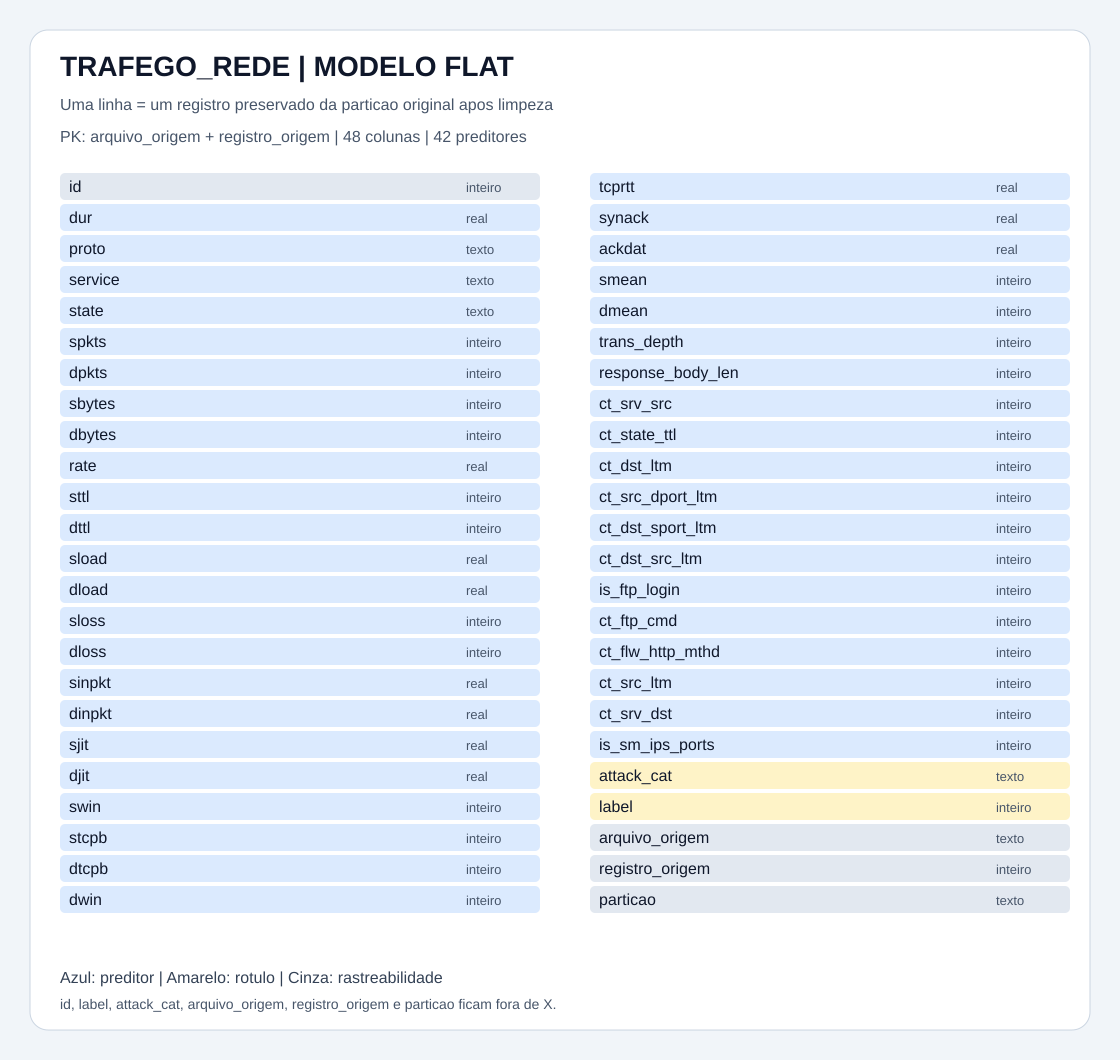

Limpeza reproduzida: todos os valores iguais à tabela histórica.


In [24]:
# União vertical preservando a partição e a chave de cada registro.
dados = pd.concat([treino.assign(particao='treino'), teste.assign(particao='teste')], ignore_index=True)
catalogo = ler_json(MODELO_REF / 'catalogo_dados.json')
categorias_observadas = ler_json(MODELO_REF / 'categorias_observadas.json')
exigir(len(catalogo) == 48 and len(features) == 42, 'Esquema inesperado.')
exigir(not dados.duplicated(CHAVE).any(), 'Chave primária repetida.')
with sqlite3.connect(MODELO_REF / 'modelo_flat.sqlite') as con:
    preservados = pd.read_sql_query('SELECT * FROM trafego_rede', con)
pd.testing.assert_frame_equal(
    dados.sort_values(CHAVE).reset_index(drop=True),
    preservados.sort_values(CHAVE).reset_index(drop=True), check_exact=True)

# A fonte confirmada complementa o catálogo sem modificar o ZIP histórico.
for campo in catalogo:
    campo['url_kaggle'] = 'https://www.kaggle.com/datasets/mrwellsdavid/unsw-nb15'
    campo['data_download_base'] = '2026-10-21'
salvar_json(SAIDA / 'catalogo_dados.json', catalogo)
pd.DataFrame(catalogo).to_csv(SAIDA / 'catalogo_dados.csv', index=False)
sql = (MODELO_REF / 'modelo_flat.sql').read_text()
(SAIDA / 'modelo_flat.sql').write_text(sql, encoding='utf-8')
# Reconstrói em arquivo temporário e substitui a saída após conferir o sucesso.
# Assim, repetir esta célula não duplica linhas nem recria tabelas existentes.
from contextlib import closing
banco = SAIDA / 'modelo_flat.sqlite'
banco_temporario = SAIDA / f'.modelo_flat_{uuid.uuid4().hex}.sqlite'
try:
    with closing(sqlite3.connect(banco_temporario)) as con:
        con.executescript(sql)
        dados.to_sql('trafego_rede', con, if_exists='append', index=False, chunksize=10000)
        con.commit()
        exigir(con.execute('PRAGMA integrity_check').fetchone()[0] == 'ok', 'Falha de integridade SQLite.')
        exigir(con.execute('SELECT COUNT(*) FROM trafego_rede').fetchone()[0] == len(dados),
               'Quantidade de registros divergente.')
        display(pd.read_sql_query('SELECT particao, COUNT(*) AS registros FROM trafego_rede GROUP BY particao', con))
    banco_temporario.replace(banco)
finally:
    banco_temporario.unlink(missing_ok=True)
display(pd.DataFrame(catalogo)[['nome', 'descricao', 'tipo_sql', 'papel', 'dominio_esperado']])
display(SVG(filename=str(MODELO_REF / 'modelo_flat.svg')))
print('Limpeza reproduzida: todos os valores iguais à tabela histórica.')


**7. Conferir a qualidade e conhecer o tráfego**

Verificamos os 48 campos: nulos, marcadores de ausência e domínios. Os detalhes ficam no CSV; a tela mostra um resumo e a distribuição das classes. Foram preservados 107.740 registros de treino e 55.945 de teste, com dez ausências codificadas por -1. Esses marcadores serão tratados no pré-processamento.

,total
nulos,0
ausencias_menos_1,10
violacoes_dominio,0


Chave composta única: True
Coerência dos rótulos: True


,normal,ataque,proporcao_ataque
particao,,,
teste,34206,21739,0.388578
treino,51890,55850,0.518378


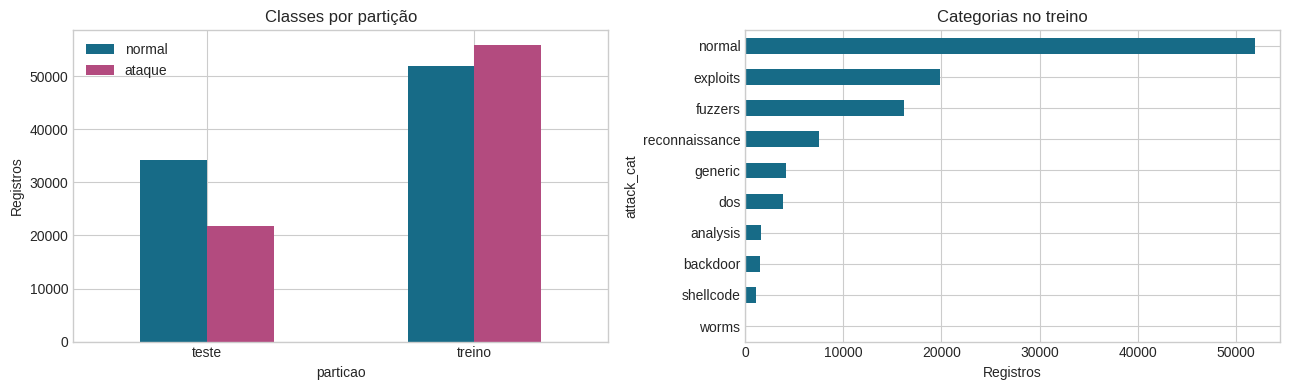

In [25]:
def avaliar_qualidade(dados, catalogo, categorias):
    linhas=[]
    for campo in catalogo:
        nome=campo["nome"];s=dados[nome]
        cat=campo["tipo_sql"]=="TEXT"
        ausencia=s.eq(-1) if campo["permite_marcador_menos_1"] else pd.Series(False,index=s.index)
        validos=s.loc[~ausencia & s.notna()]
        if cat:
            permitidos=set(categorias.get(nome,{}).get("treino",[]))|set(categorias.get(nome,{}).get("teste",[]))
            erros=s.astype(str).str.strip().eq("")
            if permitidos:erros|=~s.isin(permitidos)
            minimo=maximo=None
        else:
            erros=~np.isfinite(s.to_numpy(dtype=float))
            erros=pd.Series(erros,index=s.index)
            inferior=campo["minimo_esperado_valido"]
            superior=campo["maximo_esperado_valido"]
            if inferior is not None:erros|=(s<inferior)&~ausencia
            if superior is not None:erros|=(s>superior)&~ausencia
            if campo["tipo_sql"]=="BIGINT":erros|=(s%1!=0)&~ausencia
            minimo=None if validos.empty else float(validos.min())
            maximo=None if validos.empty else float(validos.max())
        linhas.append({"atributo":nome,"tipo":campo["tipo_sql"],"nulos":int(s.isna().sum()),
                       "ausencias_menos_1":int(ausencia.sum()),"valores_distintos":int(s.nunique()),
                       "violacoes_dominio":int(erros.sum()),"minimo_valido_observado":minimo,
                       "maximo_valido_observado":maximo,"dominio_esperado":campo["dominio_esperado"]})
    return pd.DataFrame(linhas)

qualidade = avaliar_qualidade(dados, catalogo, categorias_observadas)
exigir(qualidade.nulos.sum() == 0, 'Nulos físicos inesperados.')
exigir(qualidade.violacoes_dominio.sum() == 0, 'Há violações de domínio.')
exigir(qualidade.ausencias_menos_1.sum() == 10, 'Quantidade de ausências diferente da referência.')
qualidade.to_csv(SAIDA / 'qualidade_por_atributo.csv', index=False)
display(qualidade[["nulos", "ausencias_menos_1", "violacoes_dominio"]].sum().to_frame("total"))
print('Chave composta única:', not dados.duplicated(CHAVE).any())
print('Coerência dos rótulos:', ((dados.label == 0) == dados.attack_cat.eq('normal')).all())

# Distribuição por partição e classe, sem alterar a base.
distribuicao = dados.groupby(['particao', 'label']).size().unstack(fill_value=0)
distribuicao.columns = ['normal', 'ataque']
distribuicao['proporcao_ataque'] = distribuicao.ataque / distribuicao.sum(axis=1)
display(distribuicao)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
distribuicao[['normal', 'ataque']].plot.bar(ax=axes[0], rot=0, color=['#176b87', '#b34b7f'])
treino.attack_cat.value_counts().sort_values().plot.barh(ax=axes[1], color='#176b87')
axes[0].set(title='Classes por partição', ylabel='Registros')
axes[1].set(title='Categorias no treino', xlabel='Registros')
fig.tight_layout()
fig.savefig(SAIDA / 'graficos/composicao_atual.png', dpi=150)
plt.show()


**8. Preparar ajuste, validação e teste**

Vetores com os mesmos 42 atributos ficam juntos na divisão entre ajuste e validação. O pré-processamento aprende medianas, escalas e categorias somente no ajuste. Avaliamos o teste completo e o complemento de 53.915 registros sem vetores iguais aos do treino; esse filtro altera a população e não prova independência estatística.

In [26]:
def separar_treino_validacao(treino, features, seed):
    chaves = pd.MultiIndex.from_frame(treino[features])
    grupos, unicos = chaves.factorize(sort=False)
    divisao = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    ia, iv = next(divisao.split(treino[features], treino.label, grupos))
    exigir(not set(grupos[ia]) & set(grupos[iv]), "Vazamento de vetores entre ajuste e validacao.")
    exigir(set(treino.label.iloc[ia]) == set(treino.label.iloc[iv]) == {0, 1},
           "Ajuste e validacao precisam conter as duas classes.")
    conflitos = pd.DataFrame({"grupo": grupos, "label": treino.label}).groupby("grupo").label.nunique()
    return ia, iv, grupos, {"ajuste": len(ia), "validacao": len(iv), "grupos_treino": len(unicos),
                            "grupos_compartilhados_ajuste_validacao": 0,
                            "grupos_com_rotulos_binarios_conflitantes": int(conflitos.gt(1).sum())}

if RETREINAR_MODELOS:
    ia, iv, grupos, auditoria = separar_treino_validacao(treino, features, config['seed'])
    divisao_atual = treino[CHAVE + ['id', 'label']].copy()
    divisao_atual['grupo_atributos'] = grupos
    divisao_atual['uso'] = np.where(np.isin(np.arange(len(treino)), iv), 'validacao', 'ajuste')
else:
    original = pd.read_csv(RESULTADOS_REF / 'divisao_ajuste_validacao.csv')
    exigir(not original.duplicated(CHAVE).any(), 'Chaves repetidas na divisão salva.')
    divisao_atual = treino[CHAVE + ['id', 'label']].merge(
        original[CHAVE + ['grupo_atributos', 'uso']], on=CHAVE, how='left', validate='one_to_one')
    exigir(divisao_atual.uso.isin(['ajuste', 'validacao']).all(), 'Divisão salva incompleta.')
    ia = np.flatnonzero(divisao_atual.uso.eq('ajuste'))
    iv = np.flatnonzero(divisao_atual.uso.eq('validacao'))
    grupos, _ = pd.MultiIndex.from_frame(treino[features]).factorize(sort=False)
    auditoria = ler_json(RESULTADOS_REF / 'auditoria_divisao.json')
exigir(not set(grupos[ia]) & set(grupos[iv]), 'Mesmo vetor no ajuste e na validação.')
chaves_treino = pd.MultiIndex.from_frame(treino[features])
sobreposto = pd.MultiIndex.from_frame(teste[features]).isin(chaves_treino)
mascaras = {'teste_completo': np.ones(len(teste), dtype=bool),
            'teste_sem_sobreposicao': ~sobreposto}
exigir(int(sobreposto.sum()) == 2030, 'Sobreposição diferente da referência.')
divisao_atual.to_csv(SAIDA / 'divisao_ajuste_validacao.csv', index=False)
print(f'Ajuste: {len(ia):,}; validação: {len(iv):,}; teste: {len(teste):,}.')
print('Teste sem vetores iguais ao treino:', int((~sobreposto).sum()))
print('Cobertura do complemento:', f'{(~sobreposto).mean():.2%}')

def criar_preprocessador(features):
    numericas = [c for c in features if c not in CAT]
    num = Pipeline([
        ("imputar", SimpleImputer(missing_values=-1, strategy="median", add_indicator=True, keep_empty_features=True)),
        ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("padronizar", StandardScaler()),
    ])
    colunas = ColumnTransformer([
        ("numericas", num, numericas),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), CAT),
    ], sparse_threshold=0)
    return Pipeline([("colunas", colunas),
                     ("float32", FunctionTransformer(np.float32, feature_names_out="one-to-one"))])


def probabilidade(modelo, matriz):
    return np.asarray(modelo.predict_proba(matriz)[:, list(modelo.classes_).index(1)], dtype=float)

prep = criar_preprocessador(features)
with threadpool_limits(limits=config['threads_blas']):
    xa = prep.fit_transform(treino.iloc[ia][features])
    xv = prep.transform(treino.iloc[iv][features])
    xt = prep.transform(teste[features])
ya = treino.label.iloc[ia].to_numpy()
yv = treino.label.iloc[iv].to_numpy()
yt = teste.label.to_numpy()
for matriz in [xa, xv, xt]:
    exigir(matriz.dtype == np.float32 and np.isfinite(matriz).all(), 'Matriz transformada inválida.')
print('Matrizes ajuste / validação / teste:', xa.shape, xv.shape, xt.shape)
print('Campos excluídos de X:', sorted(set(dados.columns) - set(features)))


Ajuste: 86,175; validação: 21,565; teste: 55,945.
Teste sem vetores iguais ao treino: 53915
Cobertura do complemento: 96.37%
Matrizes ajuste / validação / teste: (86175, 194) (21565, 194) (55945, 194)
Campos excluídos de X: ['arquivo_origem', 'attack_cat', 'id', 'label', 'particao', 'registro_origem']


**9. Comparar Random Forest e rede neural**

A Random Forest usa 200 árvores. A rede possui três camadas ocultas (128/64/32), ReLU e Adam; a parada usa apenas a perda de validação, com restauração dos melhores pesos. O baseline utiliza a proporção de classes do ajuste.

Com RETREINAR_MODELOS=False, conferimos os resultados originais. Com True, treinamos novamente. Na execução original, a rede executou 31 épocas e restaurou os pesos da época 23.

Conferência: serão utilizadas as predições originais salvas, sem novo treinamento.


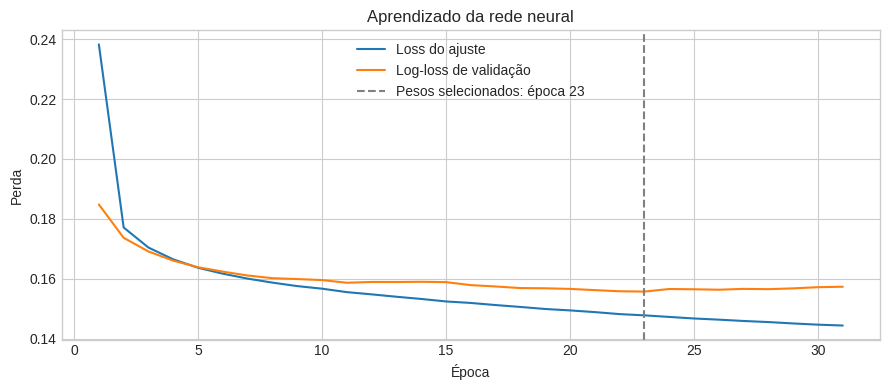

In [27]:
modelos, tempos_treino = {}, {}
if RETREINAR_MODELOS:
    modelos['RandomForest'] = RandomForestClassifier(
        n_estimators=config['arvores_rf'], min_samples_leaf=config['min_folha_rf'],
        max_features='sqrt', random_state=config['seed'], n_jobs=config['jobs_rf'])
    modelos['Baseline'] = DummyClassifier(strategy='prior')
    with threadpool_limits(limits=config['threads_blas']):
        for nome, modelo in modelos.items():
            inicio = time.perf_counter()
            modelo.fit(xa, ya)
            tempos_treino[nome] = time.perf_counter() - inicio
            print(nome, '— treinamento:', round(tempos_treino[nome], 3), 's')
else:
    print('Conferência: serão utilizadas as predições originais salvas, sem novo treinamento.')

def treinar_rede(xa, ya, xv, yv, config):
    modelo = MLPClassifier(hidden_layer_sizes=tuple(config["camadas_ocultas"]), activation="relu",
                           solver="adam", alpha=config["alpha_l2"], batch_size=config["batch_size"],
                           learning_rate_init=config["learning_rate"], early_stopping=False,
                           random_state=config["seed"], shuffle=True)
    melhor, menor, sem_melhora, epoca_melhor = None, float("inf"), 0, 0
    historico = []
    for epoca in range(1, config["epocas_maximas"] + 1):
        modelo.partial_fit(xa, ya, classes=np.array([0, 1]))
        pv = probabilidade(modelo, xv)
        perda = float(log_loss(yv, pv, labels=[0, 1]))
        exigir(np.isfinite(perda), "A rede apresentou perda nao finita.")
        historico.append({"epoca": epoca, "loss_ajuste": float(modelo.loss_), "log_loss_validacao": perda,
                          "average_precision_validacao": float(average_precision_score(yv, pv))})
        if perda < menor - config["melhoria_minima_logloss"]:
            menor, melhor, sem_melhora, epoca_melhor = perda, copy.deepcopy(modelo), 0, epoca
        else:
            sem_melhora += 1
        if epoca == 1 or epoca % 5 == 0:
            print(f"Rede — epoca {epoca}: log-loss de validacao = {perda:.5f}", flush=True)
        if sem_melhora >= config["paciencia"]:
            break
    exigir(melhor is not None and melhor.n_layers_ == 5 and len(melhor.coefs_) == 4,
           "Arquitetura esperada: entrada, tres camadas ocultas e saida.")
    print(f"Rede concluida: {epoca} epocas executadas; pesos restaurados da epoca {epoca_melhor}.", flush=True)
    return melhor, pd.DataFrame(historico), epoca_melhor

if RETREINAR_MODELOS:
    with threadpool_limits(limits=config['threads_blas']):
        inicio = time.perf_counter()
        rede, historico, melhor_epoca = treinar_rede(xa, ya, xv, yv, config)
        tempos_treino['Rede3Camadas'] = time.perf_counter() - inicio
    modelos['Rede3Camadas'] = rede
else:
    historico = pd.read_csv(RESULTADOS_REF / 'historico_rede.csv')
    melhor_epoca = resumo_original['rede_melhor_epoca']
historico.to_csv(SAIDA / 'historico_rede.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historico.epoca, historico.loss_ajuste, label='Loss do ajuste')
ax.plot(historico.epoca, historico.log_loss_validacao, label='Log-loss de validação')
ax.axvline(melhor_epoca, color='gray', linestyle='--', label=f'Pesos selecionados: época {melhor_epoca}')
ax.set(xlabel='Época', ylabel='Perda', title='Aprendizado da rede neural')
ax.legend()
fig.tight_layout()
fig.savefig(SAIDA / 'graficos/aprendizado_atual.png', dpi=150)
plt.show()


**10. Avaliar os modelos**

Precisão mede a proporção de alertas corretos; recall mede os ataques detectados; FPR mede o tráfego normal que gerou falso alerta. F1 combina precisão e recall. ROC-AUC e Average Precision (AP) avaliam o ranking dos scores.

A candidata é escolhida pela AP de validação. Os cortes 0,5 e aquele com FPR ≤ 1% na validação são congelados antes do teste. Esse alvo de 1% não é uma garantia para dados novos. As métricas originais são recalculadas com os scores salvos.

In [29]:
def escolher_limiar(y, p, fpr_alvo):
    p = np.asarray(p, dtype=float)
    fpr, tpr, limiares = roc_curve(y, p, drop_intermediate=False)
    limiares = np.asarray(limiares, dtype=float)
    limiares[~np.isfinite(limiares)] = np.nextafter(float(np.max(p)), np.inf)
    elegiveis = np.flatnonzero(fpr <= fpr_alvo + 1e-12)
    melhor = max(elegiveis, key=lambda i: (tpr[i], -fpr[i], limiares[i]))
    return {"limiar": float(limiares[melhor]), "fpr_validacao": float(fpr[melhor]),
            "recall_validacao": float(tpr[melhor]), "fpr_alvo_validacao": fpr_alvo}


def metricas(y, p, limiar):
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    exigir(len(y) > 0 and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all(), "Predicoes invalidas.")
    pred = (p >= limiar).astype(int)
    tn, fp, fn, tp = [int(v) for v in confusion_matrix(y, pred, labels=[0, 1]).ravel()]
    duas_classes = len(np.unique(y)) == 2
    return {"registros": len(y), "prevalencia_ataques": float(y.mean()), "limiar": float(limiar),
            "acuracia": float(accuracy_score(y, pred)),
            "acuracia_balanceada": float(balanced_accuracy_score(y, pred)) if duas_classes else None,
            "precisao_ataque": float(precision_score(y, pred, zero_division=0)),
            "recall_ataque": float(recall_score(y, pred, zero_division=0)),
            "f1_ataque": float(f1_score(y, pred, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, p)) if duas_classes else None,
            "average_precision": float(average_precision_score(y, p)) if np.any(y == 1) else None,
            "fpr": fp / (fp + tn) if fp + tn else None,
            "fnr": fn / (fn + tp) if fn + tp else None,
            "tn": tn, "fp": fp, "fn": fn, "tp": tp}


In [30]:
if RETREINAR_MODELOS:
    validacao_linhas, limiares, probabilidades, custos_linhas = [], {}, {}, []
    with threadpool_limits(limits=config['threads_blas']):
        for nome, modelo in modelos.items():
            pv = probabilidade(modelo, xv)
            validacao_linhas.append({'modelo': nome, **metricas(yv, pv, 0.5)})
            if nome != 'Baseline':
                limiares[nome] = escolher_limiar(yv, pv, config['fpr_alvo_validacao'])
        validacao = pd.DataFrame(validacao_linhas)
        candidato = validacao.loc[validacao.modelo != 'Baseline'].sort_values(
            ['average_precision', 'acuracia_balanceada'], ascending=False).iloc[0].modelo
        # Somente agora avaliamos o teste, com decisões congeladas.
        for nome, modelo in modelos.items():
            inicio = time.perf_counter()
            probabilidades[nome] = probabilidade(modelo, xt)
            custos_linhas.append({'modelo': nome, 'treino_segundos': tempos_treino[nome],
                                 'inferencia_teste_segundos': time.perf_counter() - inicio})
        (SAIDA / 'modelos').mkdir()
        for nome, modelo in modelos.items():
            joblib.dump(modelo, SAIDA / 'modelos' / (nome + '.joblib'), compress=3)
        joblib.dump(prep, SAIDA / 'modelos/preprocessador.joblib', compress=3)
    custos = pd.DataFrame(custos_linhas)
    predicoes = teste[CHAVE + ['id', 'label', 'attack_cat']].copy()
    predicoes['vetor_igual_ao_treino_original'] = sobreposto
    for nome, p in probabilidades.items():
        predicoes['probabilidade_' + nome] = p
else:
    referencia_pred = pd.read_csv(RESULTADOS_REF / 'predicoes_teste.csv', float_precision='round_trip')
    exigir(not referencia_pred.duplicated(CHAVE).any(), 'Chaves repetidas nas predições.')
    base = teste[CHAVE + ['label', 'attack_cat']].set_index(CHAVE)
    comparacao = referencia_pred.set_index(CHAVE).reindex(base.index)
    pd.testing.assert_frame_equal(base[['label', 'attack_cat']], comparacao[['label', 'attack_cat']])
    exigir(len(referencia_pred) == len(teste), 'Quantidade de predições divergente.')
    predicoes = comparacao.reset_index()
    exigir(np.array_equal(predicoes.vetor_igual_ao_treino_original.to_numpy(), sobreposto),
           'Sobreposição das predições divergente.')
    probabilidades = {nome: predicoes['probabilidade_' + nome].to_numpy(dtype=float)
                      for nome in ['RandomForest', 'Rede3Camadas', 'Baseline']}
    validacao = pd.read_csv(RESULTADOS_REF / 'metricas_validacao.csv', float_precision='round_trip')
    limiares = ler_json(RESULTADOS_REF / 'limiares_validacao.json')
    custos = pd.read_csv(RESULTADOS_REF / 'tempos_computacionais.csv')
    candidato = resumo_original['candidato_por_average_precision_validacao']
print('Candidata pela AP da validação:', candidato)
display(validacao)
display(pd.DataFrame(limiares).T)


Candidata pela AP da validação: RandomForest


,modelo,registros,prevalencia_ataques,limiar,acuracia,acuracia_balanceada,precisao_ataque,recall_ataque,f1_ataque,roc_auc,average_precision,fpr,fnr,tn,fp,fn,tp
0,RandomForest,21565,0.519777,0.5,0.934106,0.932899,0.914395,0.963422,0.938268,0.986854,0.987506,0.097625,0.036578,9345,1011,410,10799
1,Rede3Camadas,21565,0.519777,0.5,0.924739,0.923973,0.914548,0.943349,0.928725,0.983129,0.983924,0.095404,0.056651,9368,988,635,10574
2,Baseline,21565,0.519777,0.5,0.519777,0.500000,0.519777,1.000000,0.684018,0.500000,0.519777,1.000000,0.000000,0,10356,0,11209


,limiar,fpr_validacao,recall_validacao,fpr_alvo_validacao
RandomForest,0.843699,0.009946,0.778838,0.01
Rede3Camadas,0.921758,0.009946,0.721652,0.01


In [31]:
linhas_metricas, linhas_categoria = [], []
for nome, p in probabilidades.items():
    politicas = {'padrao_0_5': 0.5}
    if nome in limiares:
        politicas['fpr_validacao_1pct'] = limiares[nome]['limiar']
    for politica, limiar in politicas.items():
        previsto = (p >= limiar).astype(int)
        predicoes[f'predicao_{nome}_{politica}'] = previsto
        for recorte, mascara in mascaras.items():
            linhas_metricas.append({'recorte': recorte, 'modelo': nome, 'politica': politica,
                                    **metricas(yt[mascara], p[mascara], limiar)})
            parte = teste.loc[mascara, ['attack_cat', 'label']].copy()
            parte['alerta'] = previsto[mascara]
            for categoria, grupo in parte.groupby('attack_cat'):
                linhas_categoria.append({'recorte': recorte, 'modelo': nome, 'politica': politica,
                    'categoria': categoria, 'registros': len(grupo), 'alertas': int(grupo.alerta.sum()),
                    'taxa_alertas': float(grupo.alerta.mean()),
                    'interpretacao': 'FPR (normal)' if categoria == 'normal' else 'Recall (ataque)'})
resultados = pd.DataFrame(linhas_metricas)
categorias = pd.DataFrame(linhas_categoria)
if not RETREINAR_MODELOS:
    original = pd.read_csv(RESULTADOS_REF / 'metricas_teste.csv', float_precision='round_trip')
    chave_metrica = ['recorte', 'modelo', 'politica']
    atual = resultados.set_index(chave_metrica).sort_index()
    anterior = original.set_index(chave_metrica).sort_index()
    exigir(atual.index.equals(anterior.index), 'Recortes ou políticas diferentes.')
    exigir(np.array_equal(atual[['tn', 'fp', 'fn', 'tp']], anterior[['tn', 'fp', 'fn', 'tp']]),
           'Matrizes de confusão diferentes das originais.')
    for coluna in atual.columns:
        exigir(np.allclose(atual[coluna], anterior[coluna], atol=1e-10, rtol=1e-10),
               f'Métrica divergente: {coluna}')
    print('As dez linhas de métricas originais foram recalculadas e conferidas.')
for nome, tabela_resultado in [('metricas_teste', resultados), ('metricas_validacao', validacao),
                             ('predicoes_teste', predicoes), ('resultados_por_categoria', categorias),
                             ('tempos_computacionais', custos)]:
    tabela_resultado.to_csv(SAIDA / (nome + '.csv'), index=False)
salvar_json(SAIDA / 'limiares_validacao.json', limiares)
display(resultados.round(4))


As dez linhas de métricas originais foram recalculadas e conferidas.


,recorte,modelo,politica,registros,prevalencia_ataques,limiar,acuracia,acuracia_balanceada,precisao_ataque,recall_ataque,f1_ataque,roc_auc,average_precision,fpr,fnr,tn,fp,fn,tp
0,teste_completo,RandomForest,padrao_0_5,55945,0.3886,0.5000,0.8213,0.8504,0.6899,0.9810,0.8101,0.9692,0.9579,0.2802,0.0190,24621,9585,414,21325
1,teste_sem_sobreposicao,RandomForest,padrao_0_5,53915,0.3756,0.5000,0.8196,0.8516,0.6804,0.9801,0.8032,0.9677,0.9533,0.2769,0.0199,24345,9321,403,19846
2,teste_completo,RandomForest,fpr_validacao_1pct,55945,0.3886,0.8437,0.9001,0.8833,0.9255,0.8080,0.8628,0.9692,0.9579,0.0413,0.1920,32792,1414,4174,17565
3,teste_sem_sobreposicao,RandomForest,fpr_validacao_1pct,53915,0.3756,0.8437,0.8974,0.8771,0.9210,0.7952,0.8535,0.9677,0.9533,0.0411,0.2048,32284,1382,4147,16102
4,teste_completo,Rede3Camadas,padrao_0_5,55945,0.3886,0.5000,0.8206,0.8462,0.6946,0.9608,0.8063,0.9641,0.9518,0.2685,0.0392,25023,9183,852,20887
5,teste_sem_sobreposicao,Rede3Camadas,padrao_0_5,53915,0.3756,0.5000,0.8184,0.8463,0.6843,0.9585,0.7985,0.9621,0.9465,0.2659,0.0415,24713,8953,840,19409
6,teste_completo,Rede3Camadas,fpr_validacao_1pct,55945,0.3886,0.9218,0.8972,0.8798,0.9233,0.8020,0.8584,0.9641,0.9518,0.0423,0.1980,32758,1448,4305,17434
7,teste_sem_sobreposicao,Rede3Camadas,fpr_validacao_1pct,53915,0.3756,0.9218,0.8943,0.8734,0.9178,0.7893,0.8487,0.9621,0.9465,0.0425,0.2107,32234,1432,4267,15982
8,teste_completo,Baseline,padrao_0_5,55945,0.3886,0.5000,0.3886,0.5000,0.3886,1.0000,0.5597,0.5000,0.3886,1.0000,0.0000,0,34206,0,21739
9,teste_sem_sobreposicao,Baseline,padrao_0_5,53915,0.3756,0.5000,0.3756,0.5000,0.3756,1.0000,0.5461,0.5000,0.3756,1.0000,0.0000,0,33666,0,20249


**11. Interpretar os resultados**

**Execução original — teste completo, limiar 0,5:**

Modelo	Precisão	Recall	F1	FPR

**Random Forest:**	68,99%	98,10%	81,01%	28,02%

**Rede 128/64/32:**	69,46%	96,08%	80,63%	26,85%


As seis perguntas do trabalho são respondidas assim:
- P1 — Classes: ataques representam 51,84% do treino limpo e 38,86% do teste completo.
- P2 — Comparação: a Random Forest obteve maior AP na validação e foi a candidata selecionada; uma divisão não comprova superioridade estatística.
- P3 — Alarmes: o corte mais restritivo da Random Forest reduziu a FPR a 4,13%, mas o recall caiu a 80,80%. A meta de 1% da validação não se manteve no teste.
- P4 — Categorias: fuzzers teve o menor recall no complemento: 92,24% na Random Forest e 84,24% na rede.
- P5 — Sobreposição: 2.030 vetores de teste coincidem com o treino. Os dois recortes são relatados separadamente, com os mesmos pesos e limiares.
- P6 — Tempos: o treino levou 30,57 s na Random Forest e 24,26 s na rede, na máquina original. Esses tempos não estimam custos nem desempenho entre nuvens.
As saídas abaixo são da execução atual. As importâncias são descritivas, sem interpretação causal; os exemplos de alertas recomendam revisão humana.

,recorte,modelo,prevalencia_ataques,roc_auc,average_precision,acuracia_balanceada,precisao_ataque,recall_ataque,f1_ataque,fpr
0,teste_completo,RandomForest,0.3886,0.9692,0.9579,0.8504,0.6899,0.9810,0.8101,0.2802
1,teste_sem_sobreposicao,RandomForest,0.3756,0.9677,0.9533,0.8516,0.6804,0.9801,0.8032,0.2769
4,teste_completo,Rede3Camadas,0.3886,0.9641,0.9518,0.8462,0.6946,0.9608,0.8063,0.2685
5,teste_sem_sobreposicao,Rede3Camadas,0.3756,0.9621,0.9465,0.8463,0.6843,0.9585,0.7985,0.2659
8,teste_completo,Baseline,0.3886,0.5000,0.3886,0.5000,0.3886,1.0000,0.5597,1.0000
9,teste_sem_sobreposicao,Baseline,0.3756,0.5000,0.3756,0.5000,0.3756,1.0000,0.5461,1.0000


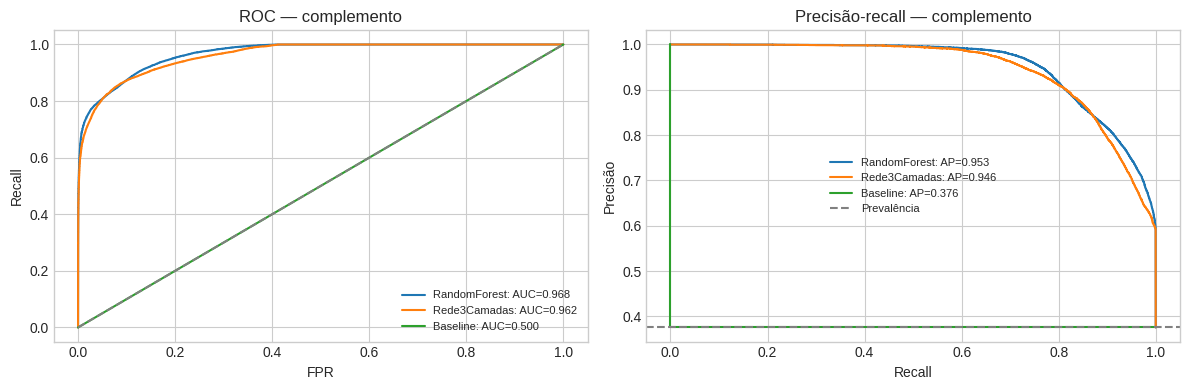

In [32]:
# Comparação atual de discriminação nos dois recortes.
comparativo = resultados.loc[resultados.politica.eq('padrao_0_5'),
    ['recorte', 'modelo', 'prevalencia_ataques', 'roc_auc', 'average_precision',
     'acuracia_balanceada', 'precisao_ataque', 'recall_ataque', 'f1_ataque', 'fpr']]
display(comparativo.round(4))
mascara = mascaras['teste_sem_sobreposicao']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for nome, p in probabilidades.items():
    fpr, tpr, _ = roc_curve(yt[mascara], p[mascara])
    precisao, recall, _ = precision_recall_curve(yt[mascara], p[mascara])
    axes[0].plot(fpr, tpr, label=f'{nome}: AUC={roc_auc_score(yt[mascara], p[mascara]):.3f}')
    axes[1].step(recall, precisao, where='post',
                 label=f'{nome}: AP={average_precision_score(yt[mascara], p[mascara]):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].axhline(yt[mascara].mean(), color='gray', linestyle='--', label='Prevalência')
axes[0].set(title='ROC — complemento', xlabel='FPR', ylabel='Recall')
axes[1].set(title='Precisão-recall — complemento', xlabel='Recall', ylabel='Precisão')
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(SAIDA / 'graficos/roc_pr_atual.png', dpi=150)
plt.show()


,modelo,politica,limiar,precisao_ataque,recall_ataque,fpr,fp,fn
0,RandomForest,padrao_0_5,0.500000,0.689906,0.980956,0.280214,9585,414
2,RandomForest,fpr_validacao_1pct,0.843699,0.925497,0.807995,0.041338,1414,4174
4,Rede3Camadas,padrao_0_5,0.500000,0.694613,0.960808,0.268462,9183,852
6,Rede3Camadas,fpr_validacao_1pct,0.921758,0.923313,0.801969,0.042332,1448,4305


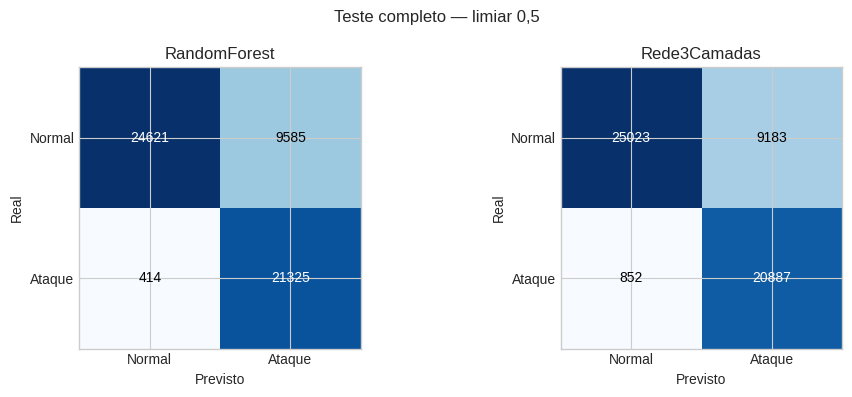

In [33]:
# Métricas operacionais: o alvo de 1% é da validação, não do teste.
operacao = resultados.loc[resultados.recorte.eq('teste_completo') & resultados.modelo.ne('Baseline')]
display(operacao[['modelo', 'politica', 'limiar', 'precisao_ataque', 'recall_ataque', 'fpr', 'fp', 'fn']])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, nome in zip(axes, ['RandomForest', 'Rede3Camadas']):
    linha = resultados.loc[resultados.recorte.eq('teste_completo') &
            resultados.modelo.eq(nome) & resultados.politica.eq('padrao_0_5')].iloc[0]
    cm = np.array([[linha.tn, linha.fp], [linha.fn, linha.tp]], dtype=int)
    ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > cm.max()/2 else 'black')
    ax.set(title=nome, xticks=[0, 1], yticks=[0, 1],
           xticklabels=['Normal', 'Ataque'], yticklabels=['Normal', 'Ataque'],
           xlabel='Previsto', ylabel='Real')
fig.suptitle('Teste completo — limiar 0,5')
fig.tight_layout()
fig.savefig(SAIDA / 'graficos/confusao_atual.png', dpi=150)
plt.show()


In [34]:
# Recall por categoria no teste complementar, mantendo o limiar 0,5.
recorte_categorias = categorias.loc[
    categorias.recorte.eq('teste_sem_sobreposicao') & categorias.politica.eq('padrao_0_5') &
    categorias.modelo.ne('Baseline') & categorias.categoria.ne('normal')]
quadro_categorias = recorte_categorias.pivot(
    index=['categoria', 'registros'], columns='modelo', values='taxa_alertas')
display(quadro_categorias)

# Comparar a composição junto com o desempenho, sem substituir o teste completo.
cobertura = pd.DataFrame([{'recorte': nome, 'registros': int(mascara.sum()),
    'cobertura': float(mascara.mean()), 'prevalencia_ataques': float(yt[mascara].mean())}
    for nome, mascara in mascaras.items()])
display(cobertura)
# A comparação das métricas dos dois recortes foi exibida acima.

print('Tempos de novo treinamento:' if RETREINAR_MODELOS else 'Tempos da execução original no Colab:')
display(custos)


,modelo,RandomForest,Rede3Camadas
categoria,registros,,
analysis,328,1.000000,1.000000
backdoor,345,1.000000,1.000000
dos,1481,0.998650,0.986496
exploits,7391,0.994994,0.988770
fuzzers,4625,0.922378,0.842378
generic,3393,0.999705,0.999411
reconnaissance,2277,0.999122,0.998243
shellcode,365,0.994521,0.994521
worms,44,1.000000,1.000000


,recorte,registros,cobertura,prevalencia_ataques
0,teste_completo,55945,1.000000,0.388578
1,teste_sem_sobreposicao,53915,0.963714,0.375573


Tempos da execução original no Colab:


,modelo,treino_segundos,inferencia_teste_segundos
0,RandomForest,30.568123,1.871892
1,Rede3Camadas,24.262945,0.103412
2,Baseline,0.004598,0.001014


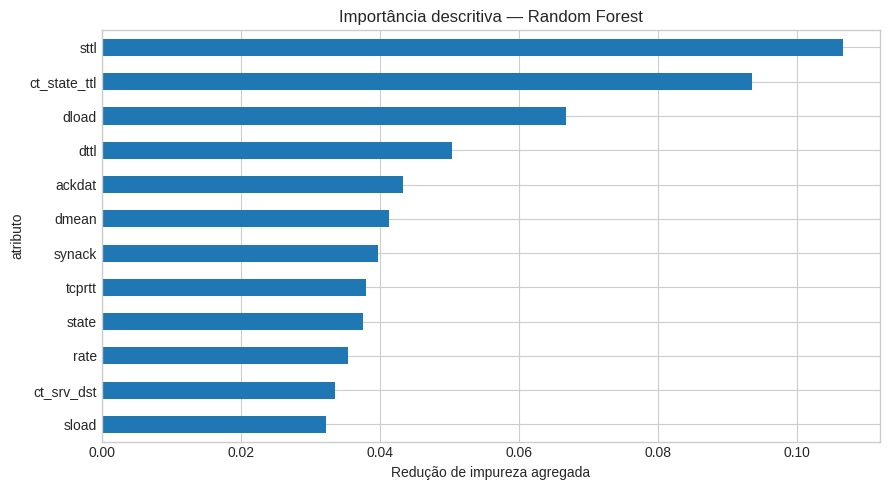

,proto,service,state,label,score,previsao,acao
0,udp,nao_identificado,int,0,0.759755,0,Monitorar
1,udp,nao_identificado,int,0,0.847095,1,Investigar evento
2,udp,nao_identificado,int,0,0.655508,0,Monitorar
3,udp,nao_identificado,int,0,0.749519,0,Monitorar
4,udp,nao_identificado,int,0,0.789368,0,Monitorar


In [35]:
def importancia_original(prep, modelo, features):
    colunas = prep.named_steps["colunas"]
    numericas = [c for c in features if c not in CAT]
    nomes_num = colunas.named_transformers_["numericas"].named_steps["imputar"].get_feature_names_out(numericas)
    mapa = [n.removeprefix("missingindicator_") for n in nomes_num]
    for nome, categorias in zip(CAT, colunas.named_transformers_["categoricas"].categories_):
        mapa.extend([nome] * len(categorias))
    exigir(len(mapa) == len(modelo.feature_importances_), "Mapeamento das importancias inconsistente.")
    return (pd.DataFrame({"atributo": mapa, "importancia_impureza": modelo.feature_importances_})
            .groupby("atributo", as_index=False).sum().sort_values("importancia_impureza", ascending=False))

if RETREINAR_MODELOS:
    importancia = importancia_original(prep, modelos['RandomForest'], features)
else:
    importancia = pd.read_csv(RESULTADOS_REF / 'importancia_rf.csv')
importancia.to_csv(SAIDA / 'importancia_rf.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
importancia.head(12).iloc[::-1].plot.barh(x='atributo', y='importancia_impureza', ax=ax, legend=False)
ax.set(title='Importância descritiva — Random Forest', xlabel='Redução de impureza agregada')
fig.tight_layout()
fig.savefig(SAIDA / 'graficos/importancia_atual.png', dpi=150)
plt.show()
alertas = teste[['proto', 'service', 'state', 'label']].head(5).copy()
alertas['score'] = probabilidades[candidato][:len(alertas)]
corte_alertas = limiares[candidato]['limiar']
alertas['previsao'] = (alertas.score >= corte_alertas).astype(int)
alertas['acao'] = np.where(alertas.previsao.eq(1), 'Investigar evento', 'Monitorar')
display(alertas)


**12. Salvar as evidências**

O ZIP reúne banco, catálogo, auditorias, métricas e gráficos, um novo treinamento fica identificado separadamente. A cópia no Drive é verificada por hash após reconexão e por uma consulta ao SQLite restaurado. Se a autorização falhar,o ZIP é inserido; a carga só é declarada concluída após a verificação.

In [38]:
# Resumo calculado a partir da execução atual.
padrao = resultados.loc[resultados.recorte.eq('teste_completo') &
                        resultados.modelo.eq(candidato) & resultados.politica.eq('padrao_0_5')].iloc[0]
operacional = resultados.loc[resultados.recorte.eq('teste_completo') &
                             resultados.modelo.eq(candidato) & resultados.politica.eq('fpr_validacao_1pct')].iloc[0]
contexto = {
    'autor': 'Magno Gomes Sousa — 200031031', 'execucao': EXECUCAO,
    'modo': 'novo_treinamento' if RETREINAR_MODELOS else 'conferencia_resultados_originais',
    'versoes_atuais': VERSOES, 'versoes_originais': manifesto_resultados['versoes'],
    'sha256_pacote_entrada': sha256(pacote_dados), 'sha256_modelo_historico': sha256(MODELO_ZIP),
    'sha256_resultados_historicos': sha256(RESULTADOS_ZIP), 'hashes_csv_originais': hashes_csv,
    'mapeamento_particoes': mapeamento, 'ajuste': len(ia), 'validacao': len(iv),
    'teste_completo': len(teste), 'teste_sem_sobreposicao': int((~sobreposto).sum()),
    'preditores': features, 'candidato_validacao': candidato,
    'epocas_rede': len(historico), 'melhor_epoca_rede': melhor_epoca,
    'armazenamento_gerado_nesta_etapa': 'local_ate_eventual_confirmacao_da_celula_drive',
}
salvar_json(SAIDA / 'contexto_execucao.json', contexto)
salvar_json(SAIDA / 'fonte_confirmada.json', fonte)
salvar_json(SAIDA / 'configuracao.json', config)
salvar_json(SAIDA / 'auditoria_divisao.json', {'ajuste': len(ia), 'validacao': len(iv),
    'grupos_compartilhados': 0, 'teste_sobreposto': int(sobreposto.sum())})
texto_resumo = (
    f'# MVP 1 — SEGURANÇA CIBERNÉTICA {EXECUCAO}\n\n'
    f'Modo: {contexto["modo"]}. Candidata selecionada na validação: {candidato}.\n\n'
    f'No teste completo, limiar 0,5: recall {padrao.recall_ataque:.2%}, '
    f'precisão {padrao.precisao_ataque:.2%}, FPR {padrao.fpr:.2%}, '
    f'FP={int(padrao.fp)}, FN={int(padrao.fn)}.\n\n'
    f'No limiar escolhido na validação ({operacional.limiar:.6f}): '
    f'recall {operacional.recall_ataque:.2%}, FPR {operacional.fpr:.2%}, '
    f'FP={int(operacional.fp)}, FN={int(operacional.fn)}.\n\n'
    'Dados de laboratório; o experimento não comprova prontidão operacional Multi-Cloud.\n'
)
(SAIDA / 'RESUMO_EXECUCAO.md').write_text(texto_resumo, encoding='utf-8')
display(Markdown(texto_resumo))

# O manifesto não contém o próprio hash, evitando uma referência circular.
hashes_saida = {str(p.relative_to(SAIDA)): sha256(p)
               for p in sorted(SAIDA.rglob('*')) if p.is_file()}
salvar_json(SAIDA / 'manifesto_execucao.json', {'execucao': EXECUCAO, 'arquivos_sha256': hashes_saida})
PACOTE_SAIDA = TRABALHO / f'MVP 1 — SEGURANÇA CIBERNÉTICA{EXECUCAO}.zip'
with zipfile.ZipFile(PACOTE_SAIDA, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(SAIDA.rglob('*')):
        if p.is_file():
            z.write(p, p.relative_to(SAIDA).as_posix())
print('Pacote criado:', PACOTE_SAIDA.name)


# MVP 1 — SEGURANÇA CIBERNÉTICA 20261021T193440Z_24d060b6

Modo: conferencia_resultados_originais. Candidata selecionada na validação: RandomForest.

No teste completo, limiar 0,5: recall 98.10%, precisão 68.99%, FPR 28.02%, FP=9585, FN=414.

No limiar escolhido na validação (0.843699): recall 80.80%, FPR 4.13%, FP=1414, FN=4174.

Dados de laboratório; o experimento não comprova prontidão operacional Multi-Cloud.


Pacote criado: MVP 1 — SEGURANÇA CIBERNÉTICA20261021T193440Z_24d060b6.zip


In [39]:
def persistir_no_drive():
    from google.colab import drive
    drive.mount('/content/drive')
    destino = Path('/content/drive/MyDrive/MVP3_Seguranca_Cibernetica') / 'relatorio_explicado' / EXECUCAO
    destino.mkdir(parents=True, exist_ok=True)
    # Copia as evidências e os três pacotes necessários à reprodução.
    shutil.copytree(SAIDA, destino / 'entrega', dirs_exist_ok=True)
    shutil.copy2(PACOTE_SAIDA, destino / PACOTE_SAIDA.name)
    for nome, arquivo in [('modelo_catalogo.zip', MODELO_ZIP),
                          ('particoes_originais.zip', ORIGINAIS_ZIP),
                          ('resultados_originais_etapa4.zip', RESULTADOS_ZIP)]:
        shutil.copy2(arquivo, destino / nome)
    hashes_drive = {'entrega/' + n: h for n, h in hashes_saida.items()}
    hashes_drive['entrega/manifesto_execucao.json'] = sha256(SAIDA / 'manifesto_execucao.json')
    hashes_drive.update({PACOTE_SAIDA.name: sha256(PACOTE_SAIDA),
        'modelo_catalogo.zip': sha256(MODELO_ZIP), 'particoes_originais.zip': sha256(ORIGINAIS_ZIP),
        'resultados_originais_etapa4.zip': sha256(RESULTADOS_ZIP)})
    drive.flush_and_unmount()
    drive.mount('/content/drive', force_remount=True)
    for nome, esperado in hashes_drive.items():
        exigir(sha256(destino / nome) == esperado, f'Cópia divergente no Drive: {nome}')
    restaurado = TRABALHO / 'banco_restaurado_drive.sqlite'
    shutil.copy2(destino / 'entrega/modelo_flat.sqlite', restaurado)
    with sqlite3.connect(restaurado) as con:
        exigir(con.execute('PRAGMA integrity_check').fetchone()[0] == 'ok', 'SQLite restaurado inválido.')
        exigir(con.execute('SELECT COUNT(*) FROM trafego_rede').fetchone()[0] == len(dados),
               'Quantidade de registros divergente após restauração.')
    recibo = {'execucao': EXECUCAO, 'tipo_destino': 'google_drive',
              'arquivos_conferidos': len(hashes_drive), 'hashes_iguais': True,
              'releitura_apos_reconexao': True, 'sqlite_restaurado_integridade': 'ok',
              'registros': len(dados), 'pasta': str(destino)}
    recibo_local = TRABALHO / 'RECIBO_DRIVE.json'
    salvar_json(recibo_local, recibo)
    shutil.copy2(recibo_local, destino / 'RECIBO_DRIVE.json')
    drive.flush_and_unmount()
    drive.mount('/content/drive', force_remount=True)
    exigir(sha256(destino / 'RECIBO_DRIVE.json') == sha256(recibo_local), 'Recibo persistido divergente.')
    print('Carga atual no Drive concluída e verificada:', destino)
    display(pd.Series(recibo).to_frame('verificação'))
    return recibo

RECIBO_DRIVE = None
if SALVAR_NO_DRIVE and EM_COLAB:
    try:
        RECIBO_DRIVE = persistir_no_drive()
    except Exception as erro:
        print('A carga atual no Drive não foi concluída:', str(erro))
        print('As saídas locais estão preservadas. Reautorize o Drive e execute novamente esta célula.')
else:
    print('Saída local pronta; não foi realizada nova carga no Drive nesta execução.')
if EM_COLAB:
    from google.colab import files
    files.download(str(PACOTE_SAIDA))
    if RECIBO_DRIVE is not None:
        files.download(str(TRABALHO / 'RECIBO_DRIVE.json'))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mounted at /content/drive
Mounted at /content/drive
Carga atual no Drive concluída e verificada: /content/drive/MyDrive/MVP3_Seguranca_Cibernetica/relatorio_explicado/20261021T193440Z_24d060b6


,verificação
execucao,20261021T193440Z_24d060b6
tipo_destino,google_drive
arquivos_conferidos,36
hashes_iguais,True
releitura_apos_reconexao,True
sqlite_restaurado_integridade,ok
registros,163685
pasta,/content/drive/MyDrive/MVP3_Seguranca_Cibernet...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**13. Conclusão**

O objetivo foi atendido: limpar, catalogar, armazenar e comparar os dois classificadores. A Random Forest é uma candidata para aprofundamento e uma maior detecção veio acompanhada de muitos falsos alarmes. Um corte mais restritivo reduziu alarmes e aumentou ataques não detectados.

o pipeline foi construido para responder às seis perguntas dentro da base disponível. As dificuldades incluíram selecionar os ZIPs corretos, compatibilizar tipos numéricos e autorizar o Drive. Em uma próxima versão, registraria previamente os custos de erro e validaria com tráfego externo, diferentes sementes e requisitos da equipe de segurança.

Limites: dados históricos de laboratório, rótulos conflitantes, deduplicação e uma divisão de validação. A base não identifica provedores, portanto não demonstra segurança Multi-Cloud nem prontidão para produção.


In [40]:
print('Dados:', len(dados), 'registros;', dados.shape[1], 'colunas;', len(features), 'preditores.')
print('Nulos físicos:', int(dados.isna().sum().sum()))
print('Ausências codificadas por -1:', int((dados[NUMERICAS] == -1).sum().sum()))
print('Métricas geradas:', len(resultados), '| Linhas por categoria:', len(categorias))
print('Carga atual no Drive:', 'verificada' if RECIBO_DRIVE is not None else 'não realizada ou não concluída')
print('Saída:', PACOTE_SAIDA)
print('Salve o notebook com as saídas: Arquivo → Salvar; ou Arquivo → Fazer download → .ipynb.')
print('Arquivos produzidos:', sum(p.is_file() for p in SAIDA.rglob('*')))


Dados: 163685 registros; 48 colunas; 42 preditores.
Nulos físicos: 0
Ausências codificadas por -1: 10
Métricas geradas: 10 | Linhas por categoria: 100
Carga atual no Drive: verificada
Saída: /content/mvp3_explicado_20261021T193440Z_24d060b6/MVP 1 — SEGURANÇA CIBERNÉTICA20261021T193440Z_24d060b6.zip
Salve o notebook com as saídas: Arquivo → Salvar; ou Arquivo → Fazer download → .ipynb.
Arquivos produzidos: 32
